# 02 — Prévoir la charge des archivistes avec Prophet

**La question :** combien d'heures d'archivistes faudra-t-il sur chaque site, semaine par semaine,
dans les mois qui viennent ?

**La démarche, en 4 essais du plus simple au plus complet :**

| # | Modèle | Ce qu'il sait |
|---|---|---|
| 0 | Baseline « l'an dernier » | rien : il recopie la même période de l'année précédente |
| 1 | Prophet seul | les rythmes (semaine, année) et la tendance |
| 2 | Prophet + événements | + les arrivées de gros clients, connues à l'avance |
| 3 | Prophet + événements, tendance plate | idem, mais sans prolonger de tendance de fond |

On entraîne sur **2021-2025** et on teste sur **2026**, une année que le modèle n'a jamais vue.

**Comment lire l'erreur (MAPE hebdo)** : c'est l'écart moyen, en %, entre les heures prévues et les heures
réelles d'une semaine. Une MAPE de 15 % sur une semaine de 150 h, c'est environ 22 h d'écart, soit à peu près
3 jours-personne. Plus c'est bas, mieux c'est.

In [1]:
from pathlib import Path
import logging, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from prophet import Prophet
from prophet.diagnostics import cross_validation

warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").disabled = True      # Prophet est bavard, on coupe ses messages
logging.getLogger("prophet").setLevel(logging.ERROR)

DATA = Path("data") if Path("data").exists() else Path("../data")
OUT = DATA.parent / "outputs"
OUT.mkdir(exist_ok=True)
plt.rcParams.update({"figure.figsize": (13, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

serie    = pd.read_csv(DATA / "prophet_charge_site.csv", parse_dates=["ds"])   # ds = date, y = heures
dim_evt  = pd.read_csv(DATA / "dim_evenement.csv", parse_dates=["date_debut", "date_fin"])
dim_date = pd.read_csv(DATA / "dim_date.csv", parse_dates=["date"])
dim_site = pd.read_csv(DATA / "dim_site.csv")
NOMS = dim_site.set_index("site_id").ville.to_dict()
SITES = sorted(serie.site_id.unique())
COUPURE = pd.Timestamp("2026-01-01")   # avant : entraînement / après : test
serie.head()

Importing plotly failed. Interactive plots will not work.


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,ds,site_id,y
0,2021-01-04,S01,58.12
1,2021-01-04,S02,28.86
2,2021-01-04,S03,20.63
3,2021-01-04,S04,24.97
4,2021-01-04,S05,22.28


## 1. Préparer ce qu'on donne à Prophet

Prophet attend un tableau avec deux colonnes : `ds` (la date) et `y` (la valeur à prévoir). On lui ajoute
deux informations métier :

**Les « holidays »** : des jours particuliers dont il doit apprendre l'effet. Ici, les **ponts** et la
**semaine entre Noël et le jour de l'an**. Les jours fériés eux-mêmes ne sont pas dans la série, puisque
personne ne travaille ces jours-là.

**Le régresseur `evt`** : pour chaque jour, le nombre de boîtes à prendre en charge au titre d'un
**événement connu à l'avance** (reprise de fonds, nouveau client, départ d'un client). On étale le volume
de l'événement sur ses jours ouvrés. Dans la vraie vie, cette info vient du commercial ou du planning
d'exploitation, avant que les camions arrivent.

> Les pics imprévus (contrôles fiscaux, audits) ne sont **pas** donnés au modèle : en 2026, personne ne les
> connaît à l'avance. Les lui donner reviendrait à tricher.

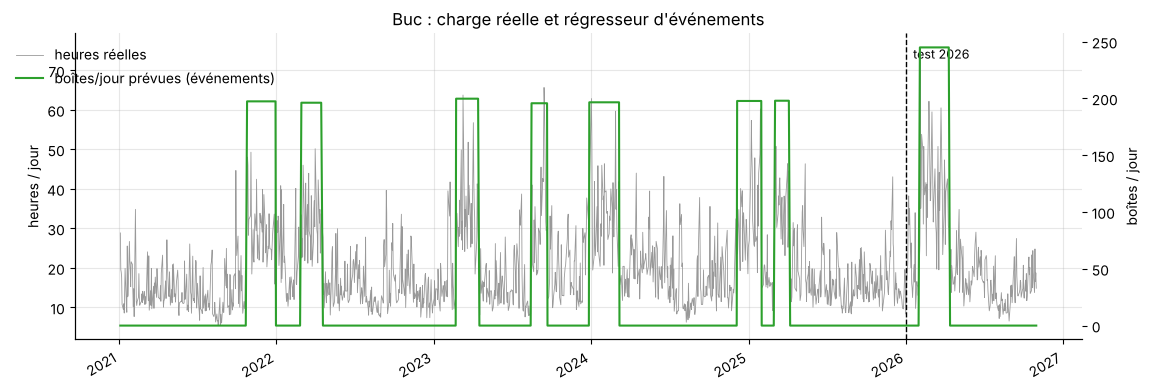

In [2]:
jours_ouvres = dim_date.loc[dim_date.est_ouvre, "date"]

def regresseur_evenements(site, dates):
    """Centaines de boîtes à traiter par jour au titre d'événements connus à l'avance."""
    r = pd.Series(0.0, index=pd.DatetimeIndex(dates))
    connus = dim_evt[(dim_evt.site_id == site) & dim_evt.connu_a_lavance]
    for _, e in connus.iterrows():
        jours = jours_ouvres[jours_ouvres.between(e.date_debut, e.date_fin)]
        r[r.index.isin(jours)] += e.nb_boites / len(jours)
    return (r / 100).values

ponts = dim_date.loc[dim_date.est_pont, ["date"]].assign(holiday="pont")
fin_annee = dim_date.loc[((dim_date.mois == 12) & (dim_date.date.dt.day >= 23))
                         | ((dim_date.mois == 1) & (dim_date.date.dt.day <= 2)), ["date"]].assign(holiday="fin_annee")
JOURS_SPECIAUX = pd.concat([ponts, fin_annee]).rename(columns={"date": "ds"})

def donnees_site(site):
    s = serie[serie.site_id == site][["ds", "y"]].reset_index(drop=True)
    s["evt"] = regresseur_evenements(site, s.ds)
    return s

# Exemple : à quoi ressemble le régresseur sur Buc
exemple = donnees_site("S02")
ax = exemple.set_index("ds").y.plot(color="0.6", lw=0.6, label="heures réelles")
ax2 = ax.twinx()
exemple.set_index("ds").evt.mul(100).plot(ax=ax2, color="C2", lw=1.5, label="boîtes/jour prévues (événements)")
ax.set(title="Buc : charge réelle et régresseur d'événements", ylabel="heures / jour", xlabel="")
ax2.set_ylabel("boîtes / jour"); ax2.grid(False)
ax.axvline(COUPURE, color="k", ls="--", lw=1)
ax.text(COUPURE, ax.get_ylim()[1] * 0.92, "  test 2026", fontsize=9)
fig = ax.figure; fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.88), frameon=False); plt.show()

**Comment lire :** en gris, les heures réelles. En vert, le volume des événements connus. Quand la courbe verte
monte, la grise monte aussi, et c'est exactement ce lien qu'on veut que Prophet apprenne. On voit aussi qu'un
événement est prévu en 2026 (la reprise des offices notariaux) : le modèle saura qu'il arrive, alors qu'il
ne l'a jamais vu.

## 2. Les quatre modèles

Une seule fonction pour entraîner et prévoir, avec trois options : régresseur oui/non, tendance linéaire ou plate.

- **Tendance linéaire** (par défaut dans Prophet) : le modèle trace une ligne de fond qui peut monter ou
  descendre, et il la prolonge dans le futur.
- **Tendance plate** : pas de ligne de fond, le niveau reste constant. Les variations viennent uniquement des
  saisons, des jours spéciaux et des événements.

In [3]:
def entrainer(train, avec_evt=False, tendance="linear"):
    m = Prophet(growth=tendance, holidays=JOURS_SPECIAUX, yearly_seasonality=True,
                weekly_seasonality=True, daily_seasonality=False)
    if avec_evt:
        m.add_regressor("evt")
    cols = ["ds", "y", "evt"] if avec_evt else ["ds", "y"]
    m.fit(train[cols])
    return m

def baseline_an_dernier(s, dates):
    """Même jour ouvré 52 semaines plus tôt ; si c'était un jour fermé, moyenne du même jour de semaine autour."""
    hist = s.set_index("ds").y
    prev = []
    for d in dates:
        v = hist.get(d - pd.Timedelta(weeks=52), np.nan)
        if np.isnan(v):
            autour = hist[(hist.index >= d - pd.Timedelta(weeks=56)) & (hist.index <= d - pd.Timedelta(weeks=48))]
            v = autour[autour.index.dayofweek == d.dayofweek].mean()
        prev.append(v)
    return np.array(prev)

MODELES = {
    "1. Prophet seul":                   dict(avec_evt=False, tendance="linear"),
    "2. + événements":                   dict(avec_evt=True,  tendance="linear"),
    "3. + événements, tendance plate":   dict(avec_evt=True,  tendance="flat"),
}

previsions = []
for site in SITES:
    s = donnees_site(site)
    train, test = s[s.ds < COUPURE], s[s.ds >= COUPURE].copy()
    test["0. Baseline an dernier"] = baseline_an_dernier(s, test.ds)
    for nom, opts in MODELES.items():
        m = entrainer(train, **opts)
        p = m.predict(test)
        test[nom] = p.yhat.clip(lower=0).values
        if nom.startswith("3."):
            test["borne_basse"], test["borne_haute"] = p.yhat_lower.clip(lower=0).values, p.yhat_upper.values
    previsions.append(test.assign(site_id=site))

previsions = pd.concat(previsions, ignore_index=True)
NOMS_MODELES = ["0. Baseline an dernier"] + list(MODELES)
previsions.head()

,ds,y,evt,0. Baseline an dernier,1. Prophet seul,2. + événements,"3. + événements, tendance plate",borne_basse,borne_haute,site_id
0,2026-01-02,25.26,0.0,45.11,17.086136,22.506666,25.718478,6.795692,44.829949,S01
1,2026-01-05,60.57,0.0,116.80,52.098512,58.489574,62.576453,44.261007,80.776565,S01
2,2026-01-06,63.58,0.0,71.31,50.781782,56.602862,60.716095,40.972334,79.530632,S01
3,2026-01-07,46.04,0.0,143.96,49.685176,54.960913,59.061327,40.744665,77.421410,S01
4,2026-01-08,44.35,0.0,121.91,50.271575,55.506912,59.675339,40.506009,78.159947,S01


## 3. Résultats sur 2026

On additionne les jours par semaine, puis on mesure l'erreur de chaque modèle.

In [4]:
def par_semaine(df, cols):
    return df.groupby(["site_id", pd.Grouper(key="ds", freq="W-SUN")])[["y"] + cols].sum().reset_index()

hebdo = par_semaine(previsions, NOMS_MODELES + ["borne_basse", "borne_haute"])
hebdo = hebdo[hebdo.y > 0]

def mape(g, col):
    return (np.abs(g[col] - g.y) / g.y).mean() * 100

tableau = pd.DataFrame({m: hebdo.groupby("site_id").apply(mape, col=m) for m in NOMS_MODELES})
tableau.loc["Moyenne"] = tableau.mean()
tableau.rename(index=NOMS).round(1)

,0. Baseline an dernier,1. Prophet seul,2. + événements,"3. + événements, tendance plate"
site_id,,,,
Villeneuve-la-Garenne,37.2,31.5,12.7,16.0
Buc,32.4,23.2,14.3,13.9
Charleval,32.4,23.4,30.7,18.6
Lesquin,38.0,57.0,21.7,21.7
Saint-Priest,89.5,138.6,17.5,15.7
Moyenne,45.9,54.7,19.4,17.2


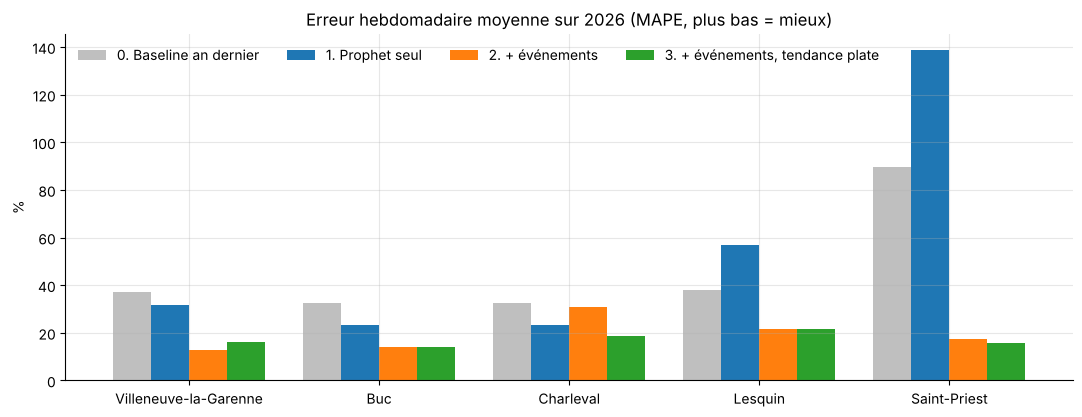

In [5]:
ax = tableau.drop("Moyenne").rename(index=NOMS).plot.bar(width=0.8, color=["0.75", "C0", "C1", "C2"])
ax.set(title="Erreur hebdomadaire moyenne sur 2026 (MAPE, plus bas = mieux)", ylabel="%", xlabel="")
ax.legend(frameon=False, ncol=4, loc="upper left"); plt.xticks(rotation=0); plt.show()

**Comment lire :** chaque groupe de barres correspond à un site, et chaque couleur à un modèle.
On cherche la barre la plus basse.

- Prophet seul (bleu) bat la baseline sur certains sites, mais il s'effondre à **Lesquin et Saint-Priest**.
  Ces deux sites ont connu une grosse reprise de fonds en 2024 et en 2025 : Prophet seul croit que c'est une
  tendance et la prolonge en 2026.
- Dès qu'on lui donne les événements (orange, vert), il comprend que ces bosses étaient ponctuelles.
  L'erreur chute partout sauf à **Charleval**, où la version orange se dégrade : voir la section 5.

**Mes observations :**
<!-- À compléter -->

## 4. Voir les prévisions semaine par semaine

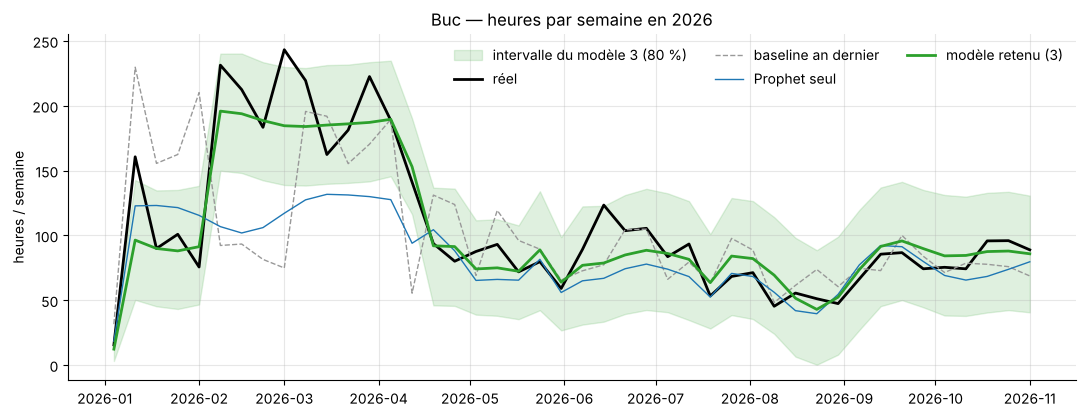

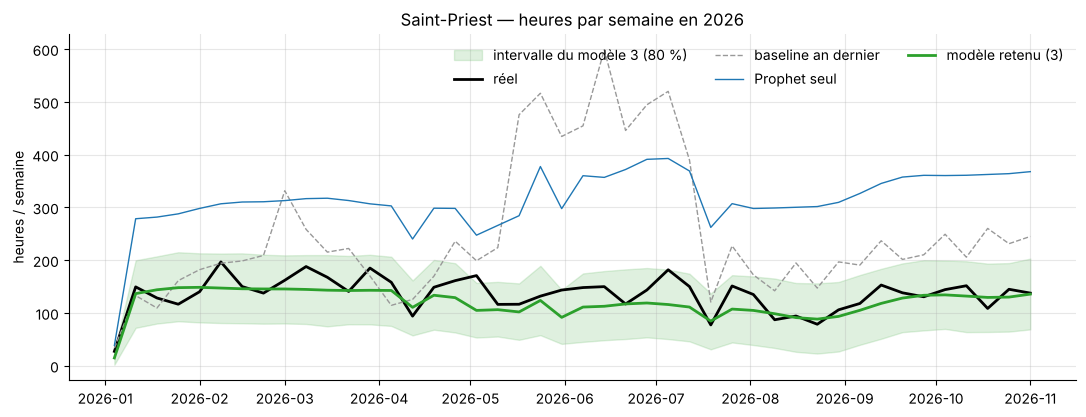

In [6]:
def tracer(site):
    h = hebdo[hebdo.site_id == site].set_index("ds")
    fig, ax = plt.subplots()
    ax.fill_between(h.index, h.borne_basse, h.borne_haute, color="C2", alpha=0.15, label="intervalle du modèle 3 (80 %)")
    ax.plot(h.y, color="k", lw=2, label="réel")
    ax.plot(h["0. Baseline an dernier"], color="0.6", lw=1, ls="--", label="baseline an dernier")
    ax.plot(h["1. Prophet seul"], color="C0", lw=1, label="Prophet seul")
    ax.plot(h["3. + événements, tendance plate"], color="C2", lw=2, label="modèle retenu (3)")
    ax.set(title=f"{NOMS[site]} — heures par semaine en 2026", ylabel="heures / semaine", xlabel="")
    ax.legend(frameon=False, ncol=3, loc="upper right"); plt.show()

for site in ["S02", "S05"]:
    tracer(site)

**Comment lire :**
- **Noir** : ce qui s'est réellement passé.
- **Vert épais** : la prévision du modèle retenu, faite au 1er janvier 2026 pour toute l'année.
- **Bande verte** : la zone où le modèle s'attend à trouver la réalité 8 fois sur 10. Si le noir en sort
  souvent, le modèle est trop sûr de lui.

À **Buc**, la reprise de février-avril est anticipée : le vert monte en même temps que le noir, même s'il
reste environ 15 % sous le pic réel. Prophet seul et la baseline ne voient rien venir.
À **Saint-Priest**, Prophet seul (bleu) et la baseline partent beaucoup trop haut, parce qu'ils recopient ou
prolongent la reprise de 2025. Le modèle retenu reste proche du réel, avec une légère sous-estimation de
mai à juillet. Les pointes que personne n'attrape correspondent aux pics imprévus (contrôles, audits).

**Mes observations :**
<!-- À compléter -->

## 5. Ce que le modèle a appris

Prophet découpe sa prévision en morceaux qu'on peut regarder un par un. C'est son gros avantage face à un
modèle « boîte noire ».

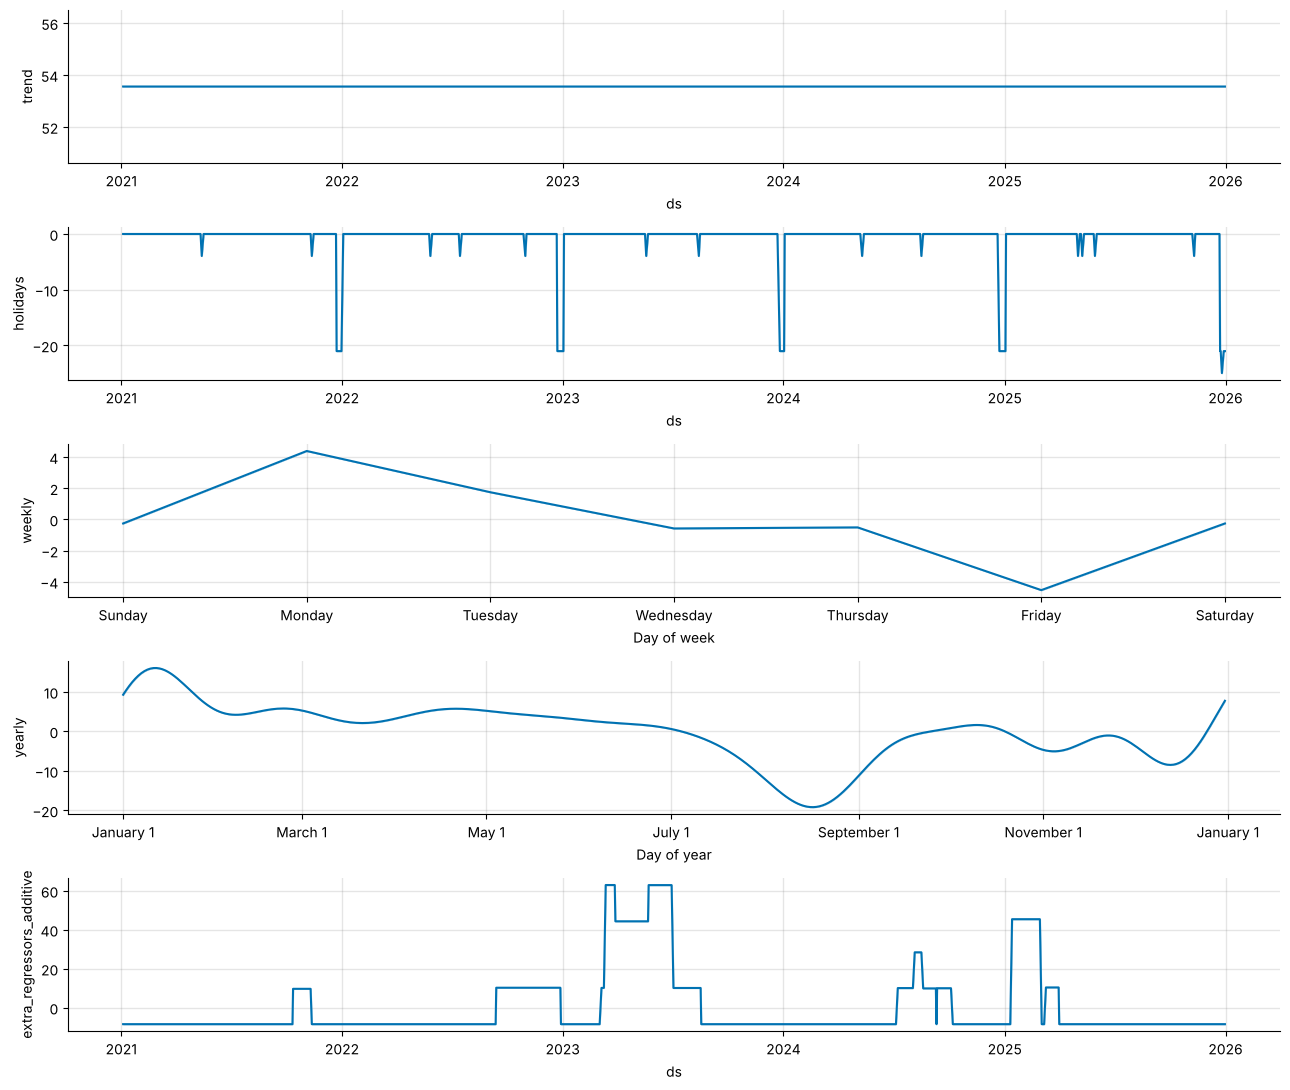

In [7]:
s = donnees_site("S01")
m_final = entrainer(s[s.ds < COUPURE], avec_evt=True, tendance="flat")
fig = m_final.plot_components(m_final.predict(s[s.ds < COUPURE]), figsize=(13, 11))
plt.show()

**Comment lire (de haut en bas), pour Villeneuve-la-Garenne :**
- **trend** : le niveau de fond. Il est plat, puisqu'on l'a choisi ainsi.
- **holidays** : l'effet des ponts et de la fin d'année, en heures (négatif = moins de travail).
- **weekly** : l'effet du jour de la semaine. Seuls lundi-vendredi comptent, les week-ends n'existent pas
  dans les données.
- **yearly** : le rythme de l'année. On retrouve le creux d'août et de décembre.
- **extra_regressors_additive** : les heures ajoutées par les événements connus. Ce sont les grosses bosses.

Pour obtenir la prévision d'un jour, Prophet additionne tous ces morceaux.

In [8]:
# Combien d'heures rapporte une centaine de boîtes d'événement ? (coefficient appris, par site)
from prophet.utilities import regressor_coefficients
coefs = []
for site in SITES:
    s = donnees_site(site)
    m = entrainer(s[s.ds < COUPURE], avec_evt=True, tendance="flat")
    coefs.append(regressor_coefficients(m).assign(site=NOMS[site])[["site", "coef"]])
coefs = pd.concat(coefs).rename(columns={"coef": "heures pour 100 boîtes/jour"}).set_index("site").round(1)
coefs

,heures pour 100 boîtes/jour
site,
Villeneuve-la-Garenne,9.4
Buc,8.3
Charleval,7.3
Lesquin,8.1
Saint-Priest,8.9


**Comment lire :** on a fixé le temps de versement à 5 minutes par boîte, donc 100 boîtes coûtent 8,3 h.
Les sites tournent tous entre 7 et 9,5 h : le modèle a retrouvé le mécanisme à partir des seules données,
sans qu'on lui donne le temps standard. Les petits écarts viennent du bruit, et du fait qu'un nouveau client
génère aussi ses premières consultations.

### Le cas Charleval : pourquoi la tendance plate ?

En tendance linéaire, Prophet trace une ligne de fond et la prolonge. À Charleval, la charge a augmenté en
2022-2023 avec deux arrivées de clients, puis elle s'est stabilisée. Une fois les événements retirés, le
modèle linéaire place la fin 2025 trop haut et surestime toute l'année 2026. Avec une tendance plate, ce
piège disparaît.

Le revers : un site qui grossit vraiment, de façon régulière, sera sous-estimé. C'est pour ça qu'on ne
peut pas trancher sur une seule année de test, d'où la section suivante.

## 6. Validation croisée : le test sur 15 périodes

Tester uniquement sur 2026 revient à juger un modèle sur un seul match. La validation croisée rejoue la
situation 15 fois : on se place à une date, on entraîne sur tout le passé disponible, on prévoit les
**8 semaines suivantes**, puis on compare au réel. On recommence 3 mois plus tard, et ainsi de suite.

8 semaines, c'est un horizon utile pour un responsable de site : le temps de recruter un intérimaire ou de
décaler des congés.

⏱️ Cette cellule prend environ 1 minute.

In [9]:
def mape_hebdo_cv(cv):
    g = cv.groupby(["cutoff", pd.Grouper(key="ds", freq="W-SUN")])[["y", "yhat"]].sum()
    g = g[g.y > 0]
    return (np.abs(g.yhat - g.y) / g.y).mean() * 100

resultats_cv, cv_final = [], []
for site in SITES:
    s = donnees_site(site)
    ligne = {"site": NOMS[site]}
    for nom, opts in MODELES.items():
        m = entrainer(s, **opts)
        cv = cross_validation(m, initial="730 days", period="91 days", horizon="56 days", disable_tqdm=True)
        cv["yhat"] = cv.yhat.clip(lower=0)
        ligne[nom] = mape_hebdo_cv(cv)
        if nom.startswith("3."):
            cv_final.append(cv.assign(site_id=site))
    # Baseline sur les mêmes périodes
    cvb = cv[["ds", "y", "cutoff"]].copy()
    cvb["yhat"] = baseline_an_dernier(s, cvb.ds)
    ligne["0. Baseline an dernier"] = mape_hebdo_cv(cvb)
    ligne["nb périodes testées"] = cv.cutoff.nunique()
    resultats_cv.append(ligne)

resultats_cv = pd.DataFrame(resultats_cv).set_index("site")[NOMS_MODELES + ["nb périodes testées"]]
resultats_cv.loc["Moyenne", NOMS_MODELES] = resultats_cv[NOMS_MODELES].mean()
resultats_cv.round(1)

,0. Baseline an dernier,1. Prophet seul,2. + événements,"3. + événements, tendance plate",nb périodes testées
site,,,,,
Villeneuve-la-Garenne,46.0,40.2,14.6,15.6,15.0
Buc,35.0,32.5,19.1,16.4,15.0
Charleval,34.7,29.6,20.4,16.7,15.0
Lesquin,52.5,40.6,18.5,18.2,15.0
Saint-Priest,39.5,38.0,16.6,16.1,15.0
Moyenne,41.5,36.2,17.8,16.6,NaN


**Comment lire :** même lecture que la section 3, mais chaque chiffre est une moyenne sur 15 périodes de
8 semaines, réparties entre 2023 et 2026. C'est un jugement beaucoup plus solide.

Le modèle 3 (événements + tendance plate) est le meilleur ou à égalité sur 4 sites sur 5, et il divise
environ par deux l'erreur de Prophet seul. C'est lui qu'on retient.

**Mes observations :**
<!-- À compléter -->

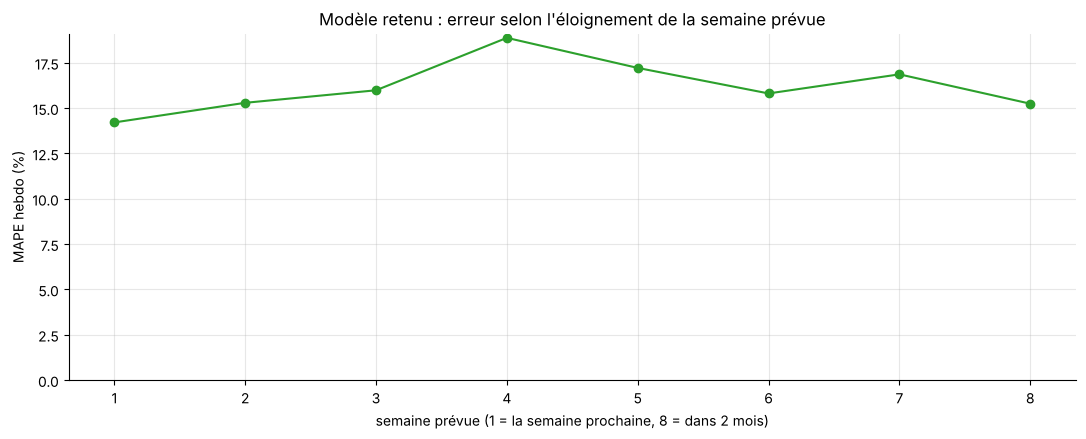

In [10]:
# L'erreur augmente-t-elle quand on prévoit plus loin ?
cvf = pd.concat(cv_final)
cvf["semaine_horizon"] = ((cvf.ds - cvf.cutoff).dt.days // 7 + 1).clip(upper=8)
g = cvf.groupby(["site_id", "cutoff", "semaine_horizon"])[["y", "yhat"]].sum()
g = g[g.y > 0]
par_horizon = (np.abs(g.yhat - g.y) / g.y * 100).groupby("semaine_horizon").mean()
ax = par_horizon.plot(marker="o", color="C2")
ax.set(title="Modèle retenu : erreur selon l'éloignement de la semaine prévue",
       xlabel="semaine prévue (1 = la semaine prochaine, 8 = dans 2 mois)", ylabel="MAPE hebdo (%)", ylim=(0, None))
plt.show()

**Comment lire :** si la courbe monte fortement, le modèle n'est fiable qu'à court terme. Une courbe à peu
près plate veut dire qu'on peut planifier 2 mois à l'avance avec la même confiance que la semaine prochaine.
C'est logique ici : le modèle s'appuie sur le calendrier et les événements planifiés, pas sur les dernières
valeurs observées.

## 7. Sauvegarder les prévisions

Pour l'étape suivante (passer des heures aux effectifs) et pour Power BI.

In [11]:
export = previsions[["ds", "site_id", "y", "0. Baseline an dernier", "1. Prophet seul",
                     "3. + événements, tendance plate", "borne_basse", "borne_haute", "evt"]].rename(columns={
    "ds": "date", "y": "heures_reelles", "0. Baseline an dernier": "prev_baseline",
    "1. Prophet seul": "prev_prophet_seul", "3. + événements, tendance plate": "prev_modele_retenu",
    "borne_basse": "prev_borne_basse", "borne_haute": "prev_borne_haute", "evt": "evt_centaines_boites"})
export.round(2).to_csv(OUT / "previsions_2026.csv", index=False)
resultats_cv.round(1).to_csv(OUT / "validation_croisee.csv")
print(f"Écrit : {OUT / 'previsions_2026.csv'} ({len(export)} lignes) et {OUT / 'validation_croisee.csv'}")

Écrit : ../outputs/previsions_2026.csv (1050 lignes) et ../outputs/validation_croisee.csv


## 8. Ce qu'on retient

<!-- À rédiger avec tes mots. Pistes :
- ce qui fait la qualité de la prévision (les événements connus, bien plus que le choix du modèle) ;
- pourquoi la tendance plate, et dans quel cas elle serait un mauvais choix ;
- la limite : les pics imprévus, que personne n'anticipe ;
- ce que ça change concrètement pour un responsable de site (horizon de 8 semaines, marge d'erreur en heures).
-->

**Étape suivante (`03_effectifs.ipynb`)** : convertir les heures prévues en nombre d'archivistes nécessaires,
les comparer à l'effectif réel, et repérer à l'avance les semaines où il faut du renfort.